# №7 зертханалық жұмыс
## Grid Search, Randomized Search және автоматты оңтайландыру әдістерін пайдаланып модель гиперпараметрлерін баптау.

Практика бірдей C/gamma аймақтарымен, 12 кандидатпен және ішкі бөліністермен нақты Wine жиынында Grid пен Randomized Search-ті салыстырады. Екі стратегия алдын ала анықталған, test бойынша жеңімпаз таңдалмайды. Nested CV тек 142 train ішінде орындалады. Таза іске қосу нәтижелерді, CSV мен атрибуцияны `lab07_artifacts` ішіне сақтайды.

Мақсат: ішкі таңдауды, бүкіл рәсімнің сыртқы бағасын және refit-тен кейінгі қорытынды тексеруді ажырату. Деректер: UCI Wine, Aeberhard & Forina, CC BY 4.0. Бұл — 178 нақты нысан, 13 белгі, үш класс; жасанды бақылаулар жоқ.

### 1-қадам Орта және келісімдер
scorer=f1_macro; Pipeline(StandardScaler,SVC(kernel='rbf')); ықтималдықтар қажет емес. Inner StratifiedKFold: 3, shuffle=True, seed=2027. Дәл теңдіктің әдеттегі ережесі cv_results_ ішіндегі ең жақсы рангтың бірінші кандидатын таңдайды. Дөңгелектеуден кейінгі теңдік дәл деп саналмайды. Nested CV ішінде бүкіл іздеу клонданады.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from scipy.stats import loguniform, norm
from sklearn.base import clone
from sklearn.datasets import load_wine
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV,
    cross_val_score)
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

ROOT = Path.cwd() / "lab07_artifacts"
FIGURES, DATASETS = ROOT / "figures", ROOT / "datasets"
FIGURES.mkdir(parents=True, exist_ok=True)
DATASETS.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
ATTRIBUTION = """Wine. Aeberhard, S. & Forina, M. (1992). UCI Machine Learning Repository.
DOI: https://doi.org/10.24432/C5PC7J
Дереккөз: https://archive.ics.uci.edu/dataset/109/wine
Лицензия: CC BY 4.0 https://creativecommons.org/licenses/by/4.0/
Көшірме sklearn.datasets.load_wine-нан экспортталған; 1-3 белгілері 0-2 ретінде берілген; баған атаулары scikit-learn-ге сәйкес.
Жасанды бақылаулар қосылмаған; қолжетімділік/метадеректер тексерілген күн: 2026-11-04.
"""



from IPython.display import display, Image
from importlib.metadata import version
for package in ("numpy", "pandas", "scipy", "scikit-learn", "matplotlib"):
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scipy 1.18.1
scikit-learn 1.9.1
matplotlib 3.11.2


### 2–4-қадамдар Деректер және іздеу кеңістіктері
Стратификацияланған split 80/20, seed=2026: 142 train және 36 test. Grid: C=[.01,1,100], gamma=[.001,.01,.1,1], 12 үйлесім. Random: loguniform(.01,100) және loguniform(.001,1), n_iter=12, seed=2027. Бірдей аймақ бірдей нүктелерді білдірмейді; логарифмдік бірқалыптылық мүмкіндікті реттік шамалар арасында бөледі. Екі стратегия бірдей ішкі фолдтарды пайдаланады.

In [2]:
def make_split():
    wine = load_wine(as_frame=True)
    X, y = wine.data, wine.target
    Xa, Xb, ya, yb = train_test_split(
        X, y, test_size=.2, stratify=y, random_state=2026)
    return {"X": X, "y": y, "train": (Xa, ya), "test": (Xb, yb)}


def make_searches():
    pipe = Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="rbf"))])
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=2027)
    shared = dict(scoring="f1_macro", cv=inner, n_jobs=1, refit=True,
                  error_score="raise")
    return {
        "Grid": GridSearchCV(pipe, {
            "model__C": [.01, 1, 100], "model__gamma": [.001, .01, .1, 1]},
            **shared),
        "Random": RandomizedSearchCV(pipe, {
            "model__C": loguniform(.01, 100),
            "model__gamma": loguniform(.001, 1)},
            n_iter=12, random_state=2027, **shared)}



split = make_split()
searches = make_searches()
print("Train/test өлшемдері:", [len(split[s][1]) for s in ["train", "test"]])
print("Тек train кластары:", np.bincount(split["train"][1], minlength=3))


Train/test өлшемдері: [142, 36]
Тек train кластары: [47 57 38]


### 5-қадам Nested CV тек train-де
Outer StratifiedKFold: 3, shuffle=True, seed=2028, тек 142 train. Әр сыртқы бөлік үшін толық search clone-ы, ішкі таңдау, refit және жеке сыртқы бағалау. Сыртқы оқыту көлемдері 94/95/95, тексеру көлемдері 48/47/47. Әр стратегияның үш macro-F1 мәні мен әдеттегі орташа шамасы сақталады; бұл сенімділік аралығы емес.

In [3]:
def nested_assessment(split, searches):
    Xa, ya = split["train"]
    outer = list(StratifiedKFold(
        n_splits=3, shuffle=True, random_state=2028).split(Xa, ya))
    output = {}
    for name, template in searches.items():
        rows = []
        for fold, (train_index, validation_index) in enumerate(outer, 1):
            search = clone(template)
            search.fit(Xa.iloc[train_index], ya.iloc[train_index])
            prediction = search.predict(Xa.iloc[validation_index])
            rows.append({
                "outer_fold": fold, "outer_train_size": len(train_index),
                "outer_validation_size": len(validation_index),
                "outer_macro_F1": f1_score(ya.iloc[validation_index], prediction,
                                          average="macro", zero_division=0),
                "best_inner_macro_F1": float(search.best_score_),
                "best_params": {k: float(v) for k, v in search.best_params_.items()},
                "refit_scaler_rows": int(search.best_estimator_.named_steps[
                    "scale"].n_samples_seen_),
                "outer_train_indices": Xa.iloc[train_index].index.tolist(),
                "outer_validation_indices": Xa.iloc[validation_index].index.tolist(),
                "candidate_count": len(search.cv_results_["params"]),
                "Pipeline_fits": len(search.cv_results_["params"]) * 3 + 1})
        output[name] = {"outer_rows": rows,
                        "mean_outer_macro_F1": float(np.mean([
                            row["outer_macro_F1"] for row in rows])),
                        "Pipeline_fits": sum(row["Pipeline_fits"] for row in rows)}
        print(name, "nested сыртқы macro-F1:",
              [row["outer_macro_F1"] for row in rows],
              "орташа:", output[name]["mean_outer_macro_F1"])
    return output



nested_result = nested_assessment(split, searches)


Grid nested сыртқы macro-F1: [0.9786453119786453, 1.0, 0.9546783625730993] орташа: 0.9777745581839149


Random nested сыртқы macro-F1: [0.9786453119786453, 0.9799587385794283, 0.9580471380471381] орташа: 0.9722170628684039


Grid: .978645, 1.000000, .954678; орташа .977775. Random: .978645, .979959, .958047; орташа .972217. Бірінші фолдта теңдік, екіншісінде Grid жоғары, үшіншісінде Random жоғары. Фолдтар байланысты, ал стратегиялар жұптап тексеріледі.

**Сіздің жауабыңыз.** Search-сіз тек модельді clone жасау неге таңдау рәсімін бағаламас еді? Бұл неге алты тәуелсіз тәжірибе емес? Бір стратегияға 3×(12×3+1)=111 Pipeline.fit есебін түсіндіріңіз.

_Өз түсіндірмеңізді жазыңыз._

### 6-қадам Негізгі іздеулер және 142 train-дегі refit
Сол алдын ала берілген стратегиялардың жеке clone-дары. Максималды орташа inner macro-F1 таңдалады, refit=True жаңа модельді бүкіл train-де оқытады. Бұл ішкі модельдердің дауыс беруі емес. Негізгі іздеу бір стратегияға 37 Pipeline.fit пайдаланады; nested-пен бірге 148, екі стратегия 296. Dummy бөлек оқытылады.

In [4]:
def fit_main(split, searches):
    Xa, ya = split["train"]
    fitted, summaries = {}, {}
    for name, template in searches.items():
        search = clone(template).fit(Xa, ya)
        fitted[name] = search
        scores = search.cv_results_
        candidates = [{"candidate_index": j,
                       "C": float(params["model__C"]),
                       "gamma": float(params["model__gamma"]),
                       "mean_inner_macro_F1": float(scores["mean_test_score"][j]),
                       "inner_fold_macro_F1": [float(scores[f"split{k}_test_score"][j])
                                                for k in range(3)],
                       "rank": int(scores["rank_test_score"][j])}
                      for j, params in enumerate(scores["params"])]
        top_indices = np.flatnonzero(scores["rank_test_score"] == 1).tolist()
        assert search.best_index_ == min(top_indices)
        summaries[name] = {
            "best_params": {k: float(v) for k, v in search.best_params_.items()},
            "best_inner_macro_F1": float(search.best_score_),
            "best_index": int(search.best_index_), "rank1_indices": top_indices,
            "candidates": candidates, "candidate_count": len(candidates),
            "Pipeline_fits": len(candidates) * 3 + 1,
            "refit_scaler_rows": int(search.best_estimator_.named_steps[
                "scale"].n_samples_seen_)}
        print(name, "негізгі ең жақсы параметрлер:", summaries[name]["best_params"],
              "ең жақсы ішкі баға:", search.best_score_, "бірінші ранг индекстері:", top_indices)
    return {"fitted": fitted, "summaries": summaries}



state = fit_main(split, searches)


Grid негізгі ең жақсы параметрлер: {'model__C': 1.0, 'model__gamma': 0.01} ең жақсы ішкі баға: 0.9790871734812044 бірінші ранг индекстері: [5]


Random негізгі ең жақсы параметрлер: {'model__C': 22.787565059790037, 'model__gamma': 0.0010167242319409676} ең жақсы ішкі баға: 0.986511764289542 бірінші ранг индекстері: [8]


Grid: C=1, gamma=.01, best inner=.979087. Random: C≈22.787565, gamma≈.001016724, best inner=.986512. Негізгі максимумдар жалғыз: нөлден санағанда 5 және 8 индекстері. Сыртқы оқытуларда параметрлер өзгеше болуы мүмкін.

**Сіздің жауабыңыз.** Best_inner, outer және test-ті ажыратыңыз. Үлкен best_inner неге жақсы қорытынды test-ке уәде бермейді? Кандидаттар реті дәл теңдікке қалай әсер етеді?

_Жауап жазыңыз._

### 10-қадамға толықтыру Жеке автоматты EI оңтайландыруы
Бұл — басқа, бірөлшемді есеп: gamma=.01 бекітілген, x=log10(C) [-2,2] аралығында. Initial x=[-2,0,2]; содан кейін қайталанусыз 201 бірқалыпты түйіннен 6 бейімделмелі ұсыныс. Функция тек Xtrain/ytrain алады. Әр objective — 142 train-дегі толық Pipeline-ның нақты үш фолдты CV-і; test берілмейді және бағаланбайды.

GPR: ConstantKernel=1 және Matern(length_scale=1,nu=2.5), екі параметр де бекітілген; optimizer=None, alpha=1e-6, normalize_y=True, seed=2027. Максимумға жеткізуге арналған EI scipy.stats.norm CDF/PDF пайдаланады. Sigma=0 кезінде max(mu-best,0) қолданылады. EI тең болса, өспелі тордың бірінші түйіні, бақыланған балдар тең болса, бірінші тексерілген нүкте алынады.

Тоғыз objective шақыруы 27 CV Pipeline.fit, содан кейін train-дегі бір соңғы fit береді: 28. Суррогаттың алты fit-і бөлек саналады. Домен мен бюджет негізгі Grid/Random-нан өзгеше, сондықтан толықтыру олардың рейтингіне кірмейді.

In [5]:
def adaptive_ei(Xtrain, ytrain):
    """Жеке бірөлшемді бейімделмелі мысал; test аргументі және оған қолжетімділік жоқ."""
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=2027)
    observed_x, observed_y, trail = [], [], []
    counters = {"objective_calls": 0, "CV_Pipeline_fits": 0,
                "final_Pipeline_fits": 0, "surrogate_fit_calls": 0}

    def evaluate(x, phase, expected_improvement=None):
        pipe = Pipeline([("scale", StandardScaler()),
                         ("model", SVC(kernel="rbf", C=10 ** x, gamma=.01))])
        scores = cross_val_score(pipe, Xtrain, ytrain, cv=inner, scoring="f1_macro",
                                 n_jobs=1, error_score="raise")
        counters["objective_calls"] += 1
        counters["CV_Pipeline_fits"] += len(scores)
        score = float(scores.mean())
        observed_x.append(float(x)); observed_y.append(score)
        trail.append({"phase": phase, "x": float(x), "C": float(10 ** x),
                      "gamma": .01, "mean_CV_macro_F1": score,
                      "fold_macro_F1": scores.tolist(),
                      "EI_at_proposal": expected_improvement})

    for x in [-2., 0., 2.]:
        evaluate(x, "initial")
    proposal_grid = np.linspace(-2, 2, 201)
    for step in range(6):
        kernel = ConstantKernel(1., constant_value_bounds="fixed") * Matern(
            length_scale=1., length_scale_bounds="fixed", nu=2.5)
        surrogate = GaussianProcessRegressor(
            kernel=kernel, optimizer=None, alpha=1e-6, normalize_y=True,
            random_state=2027)
        surrogate.fit(np.array(observed_x)[:, None], np.array(observed_y))
        counters["surrogate_fit_calls"] += 1
        unseen = proposal_grid[~np.any(np.isclose(
            proposal_grid[:, None], np.array(observed_x)[None, :],
            atol=1e-12, rtol=0), axis=1)]
        mu, sigma = surrogate.predict(unseen[:, None], return_std=True)
        improvement = mu - max(observed_y)
        ei = np.maximum(improvement, 0.)
        positive_sigma = sigma > 0
        z = improvement[positive_sigma] / sigma[positive_sigma]
        ei[positive_sigma] = (improvement[positive_sigma] * norm.cdf(z)
                              + sigma[positive_sigma] * norm.pdf(z))
        index = int(np.argmax(ei))
        evaluate(float(unseen[index]), "adaptive", float(ei[index]))
    best_index = int(np.argmax(observed_y))
    best_c = 10 ** observed_x[best_index]
    final_model = Pipeline([("scale", StandardScaler()),
                            ("model", SVC(kernel="rbf", C=best_c, gamma=.01))])
    final_model.fit(Xtrain, ytrain)
    counters["final_Pipeline_fits"] += 1
    output = {"data": "тек 142 train", "test_used": False, "dimension": 1,
              "x_definition": "log10(C)", "bounds": [-2, 2], "fixed_gamma": .01,
              "initial_x": [-2, 0, 2], "adaptive_steps": 6,
              "proposal_grid_points": 201, "trail": trail,
              "best_observed_index": best_index, "best_C": float(best_c),
              "best_observed_CV_macro_F1": float(observed_y[best_index]),
              "counters": counters,
              "total_Pipeline_fits": counters["CV_Pipeline_fits"] + counters["final_Pipeline_fits"],
              "final_scaler_rows": int(final_model.named_steps["scale"].n_samples_seen_),
              "kernel": "ConstantKernel(1,fixed)*Matern(length_scale=1,fixed,nu=2.5)",
              "optimizer": None, "alpha": 1e-6, "normalize_y": True,
              "proposal_tie_rule": "бақыланбаған өспелі x торындағы бірінші EI максимумы",
              "best_observed_tie_rule": "бірінші бақыланған максималды CV бағасы"}
    print("Жеке бірөлшемді EI, тек train:\n", pd.DataFrame(trail).to_string(index=False))
    print("EI бойынша ең жақсы C:", best_c, "бақыланған CV:", observed_y[best_index],
          "Pipeline оқыту саны:", counters["CV_Pipeline_fits"] + counters["final_Pipeline_fits"])
    return output



adaptive_result = adaptive_ei(*split["train"])


Жеке бірөлшемді EI, тек train:
    phase     x          C  gamma  mean_CV_macro_F1                                                  fold_macro_F1  EI_at_proposal
 initial -2.00   0.010000   0.01          0.190964 [0.1890547263681592, 0.19191919191919193, 0.19191919191919193]             NaN
 initial  0.00   1.000000   0.01          0.979087                  [0.9786453119786453, 0.9586162084649682, 1.0]             NaN
 initial  2.00 100.000000   0.01          0.971370    [0.9786453119786453, 0.9585057471264368, 0.976960237829803]             NaN
adaptive  0.92   8.317638   0.01          0.978487                  [0.9786453119786453, 0.9568151147098515, 1.0]        0.105138
adaptive  0.42   2.630268   0.01          0.979087                  [0.9786453119786453, 0.9586162084649682, 1.0]        0.048001
adaptive  1.50  31.622777   0.01          0.971370    [0.9786453119786453, 0.9585057471264368, 0.976960237829803]        0.040368
adaptive -0.46   0.346737   0.01          0.986449        

Бейімделмелі x: .92, .42, 1.50, -.46, -.28, 1.20. Бақыланған ең жақсы C≈.346737, CV macro-F1≈.986449. Бал бейімделуге қатысқан және тәуелсіз қорытынды баға емес. Бастапқы жолдарда EI_at_proposal жоқ, себебі олар суррогат жұмысынан бұрын берілген.

**Сіздің жауабыңыз.** Бейімделмелі ұсыныстың Random-нан айырмасын көрсетіңіз. Ең жақсы нүктенің бағасы неге тәуелсіз болмайды? Pipeline.fit-тің 27+1 шақыруын және test жоқтығын түсіндіріңіз.

_Балды әдемілеу үшін трассаны өзгертпей, түсіндірме жазыңыз._

### 7-қадам Ішкі балдар бойынша екі диаграмма
Grid жылу картасы мен Random scatter-і тек main inner CV пайдаланады. Екі ось те логарифмдік; бір түс шкаласы 0–1. Random нөмірлері — бейімделмелі траектория емес, 1-ден 12-ге дейінгі кандидаттар реті. Сақина/жақтау ішкі таңдауды білдіреді. Тор ұяшықтарының аудандары түйіндер арасындағы қосымша тексерулерді білдірмейді.

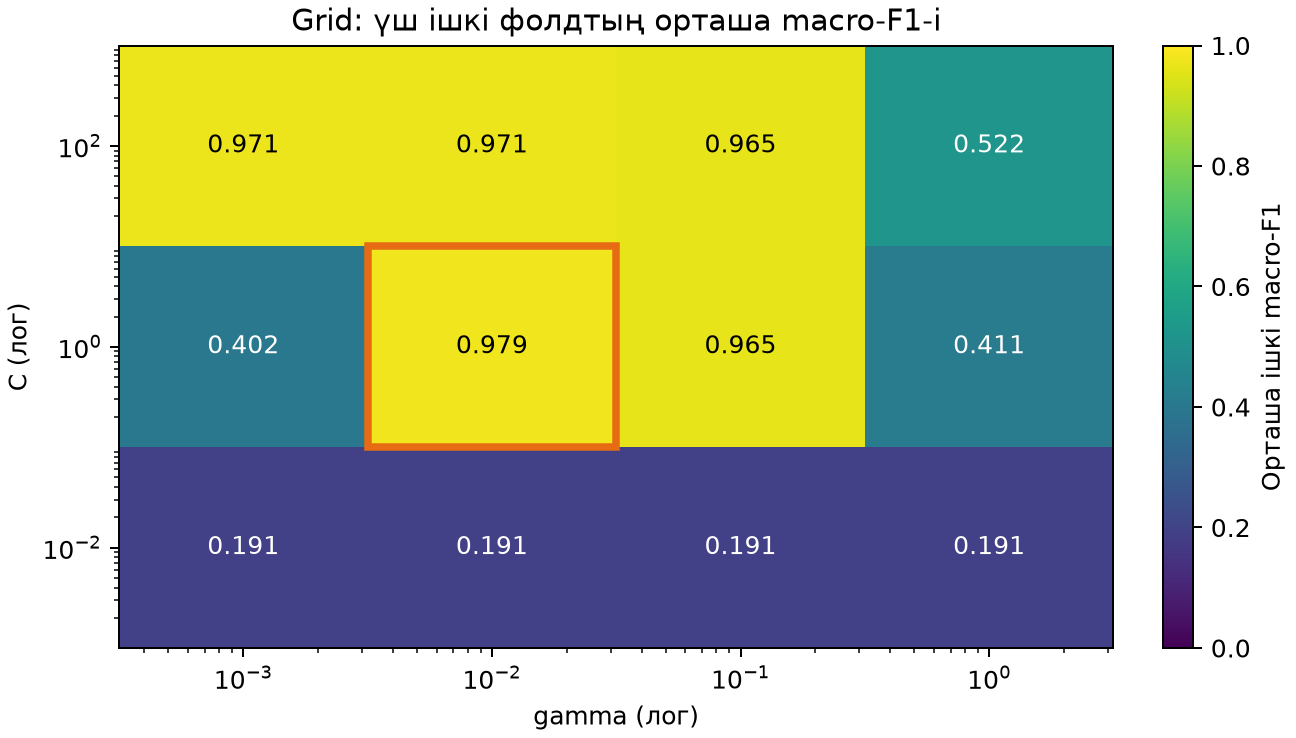

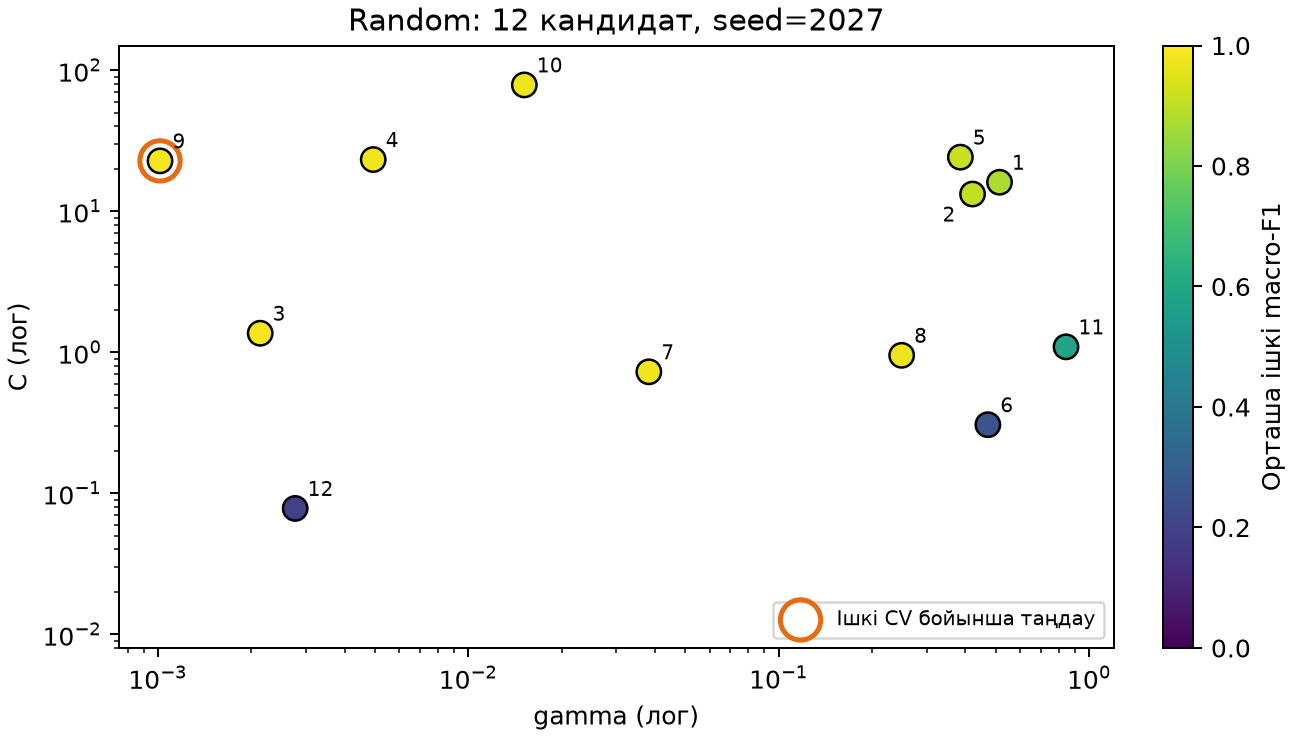

In [6]:
def plot_searches(state):
    grid = state["summaries"]["Grid"]
    cs, gammas = np.array([.01, 1, 100]), np.array([.001, .01, .1, 1])
    values = np.array([row["mean_inner_macro_F1"] for row in grid["candidates"]])
    values = values.reshape(3, 4)

    def edges(values):
        logs = np.log10(values)
        return 10 ** np.r_[logs[0] - (logs[1] - logs[0]) / 2,
                           (logs[:-1] + logs[1:]) / 2,
                           logs[-1] + (logs[-1] - logs[-2]) / 2]

    norm = Normalize(0, 1)
    ce, ge = edges(cs), edges(gammas)
    fig, ax = plt.subplots(figsize=(7.2, 4.1), layout="constrained")
    mesh = ax.pcolormesh(ge, ce, values, norm=norm, cmap="viridis", shading="flat")
    for j, c in enumerate(cs):
        for k, gamma in enumerate(gammas):
            ax.text(gamma, c, f"{values[j,k]:.3f}", ha="center", va="center",
                    fontsize=10, color="white" if values[j,k] < .65 else "black")
    j, k = divmod(grid["best_index"], 4)
    ax.add_patch(Rectangle((ge[k], ce[j]), ge[k+1]-ge[k], ce[j+1]-ce[j],
                           fill=False, edgecolor="#E66B13", linewidth=3))
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xticks=gammas, yticks=cs, xlabel="gamma (лог)", ylabel="C (лог)",
           title="Grid: үш ішкі фолдтың орташа macro-F1-і")
    fig.colorbar(mesh, ax=ax, label="Орташа ішкі macro-F1")
    fig.savefig(FIGURES / "ch07_05_grid.png", dpi=180); plt.close(fig)
    random = state["summaries"]["Random"]
    rows = random["candidates"]
    fig, ax = plt.subplots(figsize=(7.2, 4.1), layout="constrained")
    points = ax.scatter([r["gamma"] for r in rows], [r["C"] for r in rows],
                        c=[r["mean_inner_macro_F1"] for r in rows],
                        norm=norm, cmap="viridis", s=95, edgecolors="black")
    for row in rows:
        ax.annotate(str(row["candidate_index"] + 1), (row["gamma"], row["C"]),
                    xytext=(-12, -11) if row["candidate_index"] == 1 else (5, 5),
                    textcoords="offset points", fontsize=8)
    best = rows[random["best_index"]]
    ax.scatter([best["gamma"]], [best["C"]], s=260, facecolors="none",
                edgecolors="#E66B13", linewidths=2, label="Ішкі CV бойынша таңдау")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlim=(.00075, 1.2), ylim=(.008, 150), xlabel="gamma (лог)", ylabel="C (лог)",
           title="Random: 12 кандидат, seed=2027")
    ax.legend(fontsize=8, loc="lower right")
    fig.colorbar(points, ax=ax, label="Орташа ішкі macro-F1")
    fig.savefig(FIGURES / "ch07_06_random.png", dpi=180); plt.close(fig)



plot_searches(state)
display(Image(filename=str(FIGURES / "ch07_05_grid.png")))
display(Image(filename=str(FIGURES / "ch07_06_random.png")))


**Сіздің жауабыңыз.** Scatter-дің бос орны неліктен төмен сапаны білдірмейді? Жақын .986449 және .986512 неліктен дәл әмбебап оптимумды анықтамайды? Екі суреттегі масштаб пен түстің мағынасын салыстырыңыз.

_Түсіндірмеңізді жазыңыз._

### 8–9-қадамдар Екі берілген рәсім үшін бір қорытынды test
DummyPrior сол train-де оқытылады. Шынайы кластар 0/1/2 жолдарында, болжанғандар 0/1/2 бағандарында орналасқан Accuracy, macro-F1 және CM аламыз. Қорытынды 36 жол стратегияны, параметрлерді, seed-ті немесе аймақты өзгертуге пайдаланылмайды. Wine_search.csv CSV файлы мен атрибуция файлы бөлек сақталады; бұрын жасалған wine_sklearn.csv қайта жазылмайды.

In [7]:
def evaluate_test(split, state):
    Xa, ya = split["train"]
    Xb, yb = split["test"]
    models = {"DummyPrior": DummyClassifier(strategy="prior").fit(Xa, ya),
              **state["fitted"]}
    rows = []
    for name, model in models.items():
        prediction = model.predict(Xb)
        rows.append({"model": name, "Accuracy": accuracy_score(yb, prediction),
                     "macro_F1": f1_score(yb, prediction, average="macro", zero_division=0),
                     "confusion_matrix": confusion_matrix(yb, prediction,
                                                          labels=[0, 1, 2]).tolist()})
    print("Екі стратегия бекітілгеннен кейінгі бір test:\n",
          pd.DataFrame(rows).to_string(index=False))
    return rows


def save_data_and_results(split, nested, state, test_rows):
    Xa, ya = split["train"]
    Xb, yb = split["test"]
    service = pd.Series("test", index=split["X"].index)
    service.loc[Xa.index] = "train"
    split["X"].assign(target=split["y"], split=service).to_csv(
        DATASETS / "wine_search.csv", index=False)
    attribution = DATASETS / "Wine_Attribution.txt"
    if not attribution.exists():
        attribution.write_text(ATTRIBUTION, encoding="utf-8")
    return {"dataset": "нақты UCI Wine", "license": "CC BY 4.0", "shape": [178, 13],
            "sizes": [len(ya), len(yb)], "split_seed": 2026,
            "inner_CV": {"n_splits": 3, "shuffle": True, "seed": 2027},
            "outer_CV": {"n_splits": 3, "shuffle": True, "seed": 2028,
                         "data": "тек 142 train"},
            "train_class_counts": np.bincount(ya, minlength=3).tolist(),
            "test_class_counts": np.bincount(yb, minlength=3).tolist(),
            "train_indices": Xa.index.tolist(), "test_indices": Xb.index.tolist(),
            "nested": nested, "main_search": state["summaries"], "test_rows": test_rows,
            "tie_rule": "cv_results_ ретіндегі rank1 арасындағы бірінші кандидат",
            "strategies_predeclared": ["Grid", "Random"], "selected_strategy": None,
            "test_used_to_select": False,
            "Pipeline_fits_per_strategy": {"main": 37, "nested": 111, "total": 148},
            "all_search_Pipeline_fits": 296,
            "fit_unit": "бір Pipeline.fit; SVC-дің бір жұптық екілік ішкі есебі емес"}



test_rows = evaluate_test(split, state)
result = save_data_and_results(split, nested_result, state, test_rows)
result["adaptive_EI"] = adaptive_result
(ROOT / "lab07_results.json").write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")


Екі стратегия бекітілгеннен кейінгі бір test:
      model  Accuracy  macro_F1                     confusion_matrix
DummyPrior  0.388889  0.186667 [[0, 12, 0], [0, 14, 0], [0, 10, 0]]
      Grid  1.000000  1.000000 [[12, 0, 0], [0, 14, 0], [0, 0, 10]]
    Random  0.972222  0.974321 [[12, 0, 0], [1, 13, 0], [0, 0, 10]]


33223

Dummy: Accuracy=.388889, macro-F1=.186667. Grid: осы 36 жолда 1 және 1. Random: .972222 және .974321, 1→0 класында бір қате. Random-да кластар бойынша macro-F1 .96, 26/27, 1; бұл Accuracy=35/36-дан өзгеше. Grid сәттілігі оны test бойынша таңдап, сол жолдармен қайта бағалауға рұқсат бермейді.

**Сіздің жауабыңыз.** Матрицадан macro-F1-ді қалпына келтіріп, 36 нысан шектеуін түсіндіріңіз. Қандай қосымша шешімдер test-ті validation-ға айналдырар еді?

_Есептеу мен қорытындыны жазыңыз._

### Хаттама мен сақталған есептеулерді өзіндік тексеру
Бюджеттер, бірдей ішкі бөліністер, scaler-fit өлшемдері, сыртқы бөліктердің қиылыспауы және nested ішінде test қолжетімсіздігі тексеріледі. Өзіндік тексеру стратегия таңдамайды және үш сыртқы бағаны сенімділік аралығына айналдырмайды.

In [8]:
assert result["shape"] == [178, 13] and result["sizes"] == [142, 36]
train_ids, test_ids = set(result["train_indices"]), set(result["test_indices"])
assert not train_ids & test_ids
Xa, ya = split["train"]
inner_grid = list(searches["Grid"].cv.split(Xa, ya))
inner_random = list(searches["Random"].cv.split(Xa, ya))
for (ta, va), (tb, vb) in zip(inner_grid, inner_random):
    assert np.array_equal(ta, tb) and np.array_equal(va, vb)
    assert not set(ta) & set(va)
for name in ["Grid", "Random"]:
    main = result["main_search"][name]
    assert main["candidate_count"] == 12 and main["Pipeline_fits"] == 37
    assert main["refit_scaler_rows"] == 142
    assert main["best_index"] == min(main["rank1_indices"])
    assert isinstance(state["fitted"][name].estimator, Pipeline)
    assert state["fitted"][name].estimator.named_steps["model"].kernel == "rbf"
    for candidate in main["candidates"]:
        assert .01 <= candidate["C"] <= 100 and .001 <= candidate["gamma"] <= 1
        np.testing.assert_allclose(candidate["mean_inner_macro_F1"],
                                   np.mean(candidate["inner_fold_macro_F1"]))
    outer = result["nested"][name]
    assert len(outer["outer_rows"]) == 3 and outer["Pipeline_fits"] == 111
    all_validation = []
    for row in outer["outer_rows"]:
        a, b = set(row["outer_train_indices"]), set(row["outer_validation_indices"])
        assert not a & b and a | b == train_ids and not (a | b) & test_ids
        assert row["refit_scaler_rows"] == row["outer_train_size"]
        assert row["candidate_count"] == 12 and row["Pipeline_fits"] == 37
        all_validation.extend(row["outer_validation_indices"])
    assert len(all_validation) == len(set(all_validation)) == 142
for row in result["test_rows"]:
    matrix = np.array(row["confusion_matrix"])
    assert matrix.shape == (3, 3) and matrix.sum() == 36
    np.testing.assert_allclose(row["Accuracy"], np.trace(matrix) / 36)
assert result["selected_strategy"] is None and not result["test_used_to_select"]
assert result["all_search_Pipeline_fits"] == 296
ei = result["adaptive_EI"]
assert not ei["test_used"] and ei["final_scaler_rows"] == 142
assert ei["counters"] == {"objective_calls": 9, "CV_Pipeline_fits": 27,
    "final_Pipeline_fits": 1, "surrogate_fit_calls": 6}
assert ei["total_Pipeline_fits"] == 28 and len(ei["trail"]) == 9
assert len(set(row["x"] for row in ei["trail"])) == 9
assert [row["x"] for row in ei["trail"][:3]] == [-2, 0, 2]
assert all(-2 <= row["x"] <= 2 and row["gamma"] == .01 for row in ei["trail"])
for row in ei["trail"]:
    assert len(row["fold_macro_F1"]) == 3
    np.testing.assert_allclose(row["mean_CV_macro_F1"], np.mean(row["fold_macro_F1"]))
print("Шекаралар, бюджеттер және арифметика бойынша өзін-өзі тексеру өтті.")


Шекаралар, бюджеттер және арифметика бойынша өзін-өзі тексеру өтті.


### 10-қадам Ішкі нұсқа, есеп және қорғау
Нұсқаларды train ішінде орындаңыз; бастапқы test қорытынды бөлік рөлін сақтайды.

1. Сол шекаралардағы алдын ала жарияланған 12 түйінді екі тор.
2. Барлық трассаны сақтайтын алдын ала жарияланған үш Random seed-і.
3. Бірдей бюджетте loguniform және сызықтық бірқалыптылық.
4. Fit санын қайта есептеумен ішкі 3 және 5 фолд.
5. Train ішіндегі әртүрлі таңдау критерийлері ретінде macro-F1 және Accuracy.
6. Орташалары тең жасанды кесте, кандидаттар реті және дөңгелектеу.

**Сіздің нұсқаңыз, критерийіңіз, баптау көзі және қорытындыңыз.**

_Өз зерттеуіңізді қосыңыз._

Есеп: деректер/лицензия, Pipeline, кеңістіктер, seeds, кандидаттар, nested бағалары, жеке EI трассасы, 7.3–7.4-кестелер, 7.5–7.6-суреттер, матрицалар, бюджеттер, шектеулер, CSV/атрибуция/JSON/нұсқалар. Жергілікті рубрика 100%: қойылым — 15%, іздеу — 25%, nested — 20%, түсіндіру — 20%, нұсқа — 10%, қайта өндірілу — 10%. Ол ресми балды алмастырмайды.

Бақылау сұрақтары:

1. Бірдей аймақтар мен бюджеттер неліктен бірдей нүктелер бермейді?
2. Loguniform реттік шамалар арасында ықтималдықты қалай бөледі?
3. Pipeline неліктен search ішінде орналасқан?
4. Refit не істейді?
5. Best_inner outer және test-тен несімен өзгеше?
6. Әр outer-фолдта бүкіл іздеудің clone-ы неге қажет?
7. Неліктен үш outer бағасы дайын сенімділік аралығын құрмайды?
8. 37 және 111 Pipeline.fit және EI толықтыруының жеке 28 fit-і қалай шығады?
9. Ең жақсы орташалардың дәл теңдігі қалай шешіледі?
10. Стратегияны test бойынша таңдап, оны қайта тәуелсіз деуге неге болмайды?

Дереккөздер: [UCI Wine](https://archive.ics.uci.edu/dataset/109/wine), [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html), [loguniform](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.loguniform.html), [nested CV](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [GPR](https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html), бекітілген силлабус. Тексерілген күні: 2026 жылғы 4 қараша.